# Proyek Regresi Linear Otomotif
**Bayu Muhammad Ramadhan | 301240008 | Kelas 5A**

Tujuan: mengestimasi efisiensi bahan bakar di jalan raya (MPG) menggunakan kapasitas mesin (liter).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

df = pd.read_csv("mpg.csv")
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (234, 11)


,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
0,audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
1,audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
2,audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
3,audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
4,audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact


In [2]:
data = df[["displ", "hwy"]].dropna().copy()
print("Nilai kosong:\n", data.isna().sum())
print(data.describe())

Nilai kosong:
 displ    0
hwy      0
dtype: int64
            displ         hwy
count  234.000000  234.000000
mean     3.471795   23.440171
std      1.291959    5.954643
min      1.600000   12.000000
25%      2.400000   18.000000
50%      3.300000   24.000000
75%      4.600000   27.000000
max      7.000000   44.000000


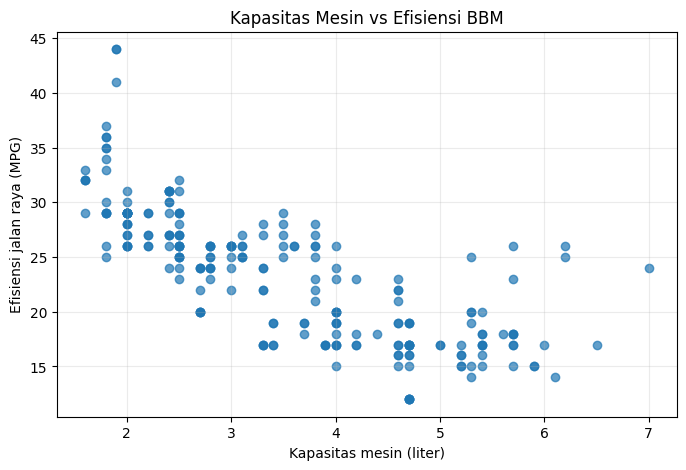

Korelasi Pearson: -0.7660200208864681


In [3]:
plt.figure(figsize=(8,5))
plt.scatter(data["displ"], data["hwy"], alpha=.7)
plt.xlabel("Kapasitas mesin (liter)")
plt.ylabel("Efisiensi jalan raya (MPG)")
plt.title("Kapasitas Mesin vs Efisiensi BBM")
plt.grid(alpha=.25)
plt.show()
print("Korelasi Pearson:", data["displ"].corr(data["hwy"]))

In [4]:
X = data[["displ"]]
y = data["hwy"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
r2 = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
print(f"Intersep: {model.intercept_:.4f}")
print(f"Koefisien displ: {model.coef_[0]:.4f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE: {rmse:.4f} MPG")
print(f"MAE: {mae:.4f} MPG")

Intersep: 36.1620
Koefisien displ: -3.6528
R-squared: 0.5275
RMSE: 3.5391 MPG
MAE: 2.4844 MPG


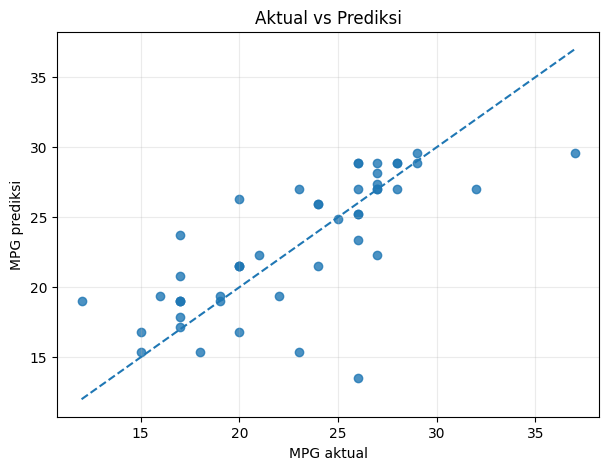

['model.joblib']

In [5]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, pred, alpha=.8)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
plt.plot([lo, hi], [lo, hi], "--")
plt.xlabel("MPG aktual"); plt.ylabel("MPG prediksi")
plt.title("Aktual vs Prediksi")
plt.grid(alpha=.25); plt.show()
joblib.dump(model, "model.joblib")

## Interpretasi dan batasan
Koefisien negatif menunjukkan bahwa di dalam dataset ini kapasitas mesin yang lebih besar cenderung berhubungan dengan MPG jalan raya yang lebih rendah. Model hanya memakai satu fitur sehingga tidak mengontrol bobot kendaraan, jenis transmisi, jumlah silinder, tipe bodi, atau variabel lain. Hasil tidak boleh dianggap hubungan sebab-akibat mutlak.